Current working directory: e:\Jan-2026\Bayseian\Projects\project-1
Looking for file: train.csv
File exists? True

First 8 lines of the file (exact content):
Line  1: '687794,2132718,364024,3273020,4589838,4507085,1960267,2256427,4276950,1065617,4494872,4309736,2747594,2639545,3956179,3952631,3277091,3424347,1854450,2368911,3346266,3381797,1140539,4156800,3263862,1631931,917608,69032,293419,2840879,3344466,2405990,1000879,402872,2256683,4758144,3153825,1822375,3091489,4178277,2985648,49007,2846365,760273,1100460,2488481,4752776,4720198,2612689,1893774,2973900,3910493,234477,1075152,1782043,1869690,1713108,4763554,2707846,2511740,1614162,32423,1353971,2288064,809913,819948,58056,1224868,10715,3116729,2031176,4312991,4604963,3413597,3521673,1783702,323790,2914449,78828,4075484,2527326,2623624,1015034,4588935,964953,4139667,406619,1823789,2158045,1126142,158722,4693034,3269524,4148951,1672222,4505542,1071171,4160881,1970842,932112,718154,2169630,352996,2931110,1213190,366718,2482027,473817

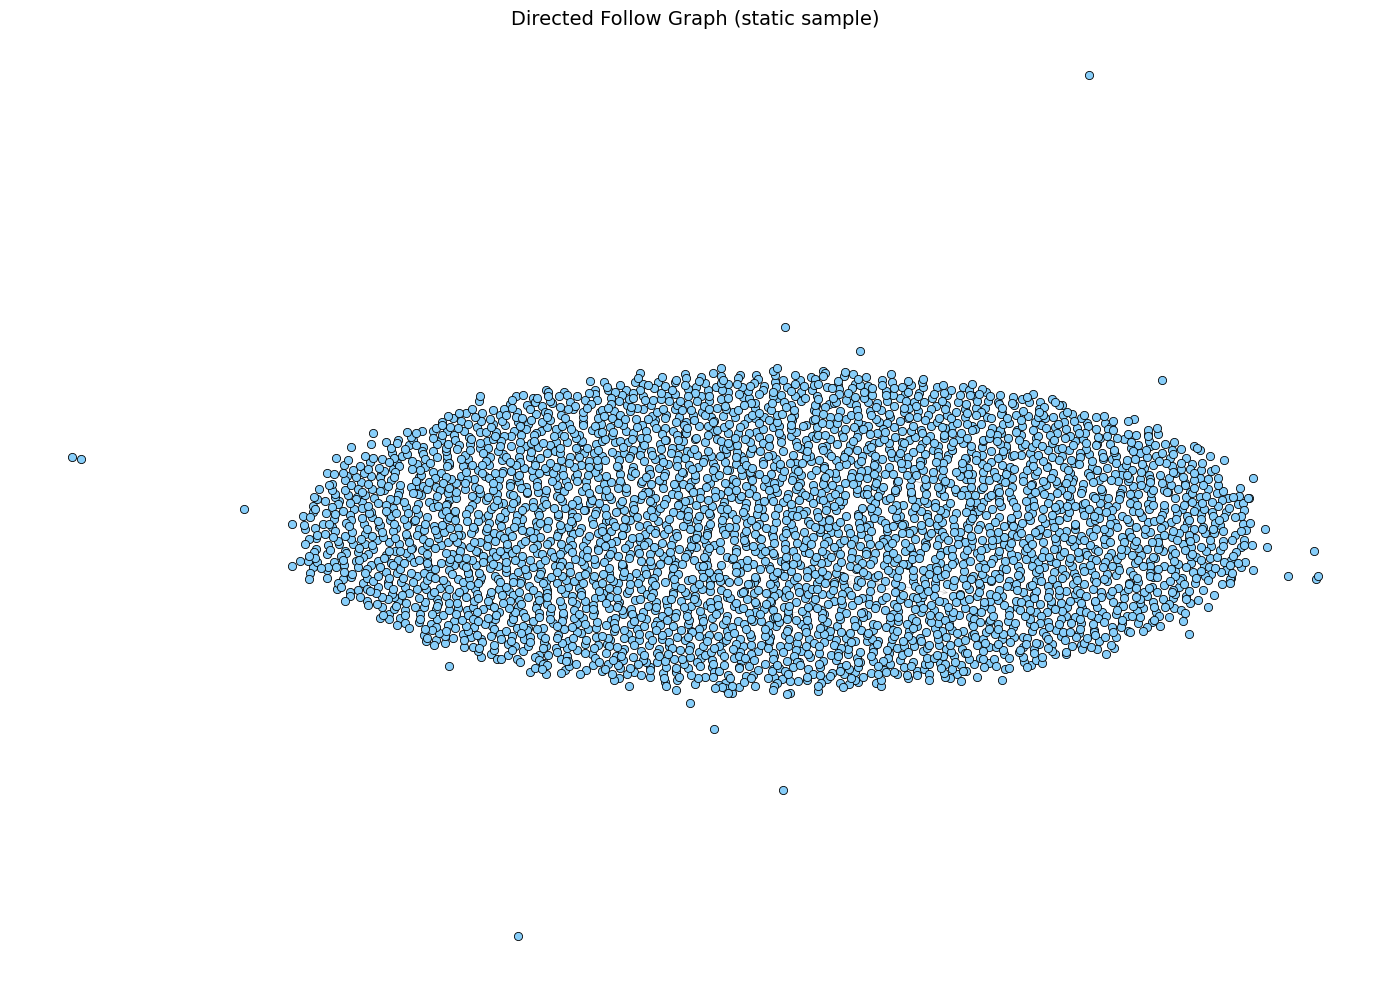


Creating interactive HTML file → follow_graph.html


AssertionError: non existent node '687794'

In [3]:
# =============================================================================
# Updated script to visualize follow graph from train.csv
# - FIXED: comma-separated format (not space-separated)
# - Safety checks for empty graph
# - Detailed file diagnostics
# =============================================================================

import networkx as nx
import matplotlib.pyplot as plt
from pyvis.network import Network
import os
import random

# ────────────────────────────────────────────────
#  CONFIGURATION
# ────────────────────────────────────────────────

# Change this to the real path if needed
# Examples:
#   Windows: r"C:\Users\Yakshith\Downloads\train.csv"
#   Colab:   "/content/train.csv"
DATA_FILE = "train.csv"               # ← change if file is not in current folder

OUTPUT_HTML = "follow_graph.html"

USE_PHYSICS_IN_PYVIS = True           # False = faster but less nice layout
NODE_SIZE_STATIC = 35
EDGE_WIDTH = 0.4
ARROW_SIZE = 8

# For very large graphs – filter to make visualization usable
MIN_DEGREE = None                     # e.g. 5 or 10 to show only more connected nodes
MAX_NODES_FOR_STATIC_PLOT = 4000     # safety limit for matplotlib

# ────────────────────────────────────────────────
#  1. Diagnostic: show file content
# ────────────────────────────────────────────────

print("Current working directory:", os.getcwd())
print("Looking for file:", DATA_FILE)
print("File exists?", os.path.exists(DATA_FILE))

if not os.path.exists(DATA_FILE):
    print("\n!!! FILE NOT FOUND !!!")
    print("Fixes:")
    print("  • Put train.csv in current folder →", os.getcwd())
    print("  • Or set DATA_FILE = r'full\\path\\to\\train.csv'")
    print("  • In Colab: upload file or mount Drive")
    raise FileNotFoundError(f"Cannot find {DATA_FILE}")

# Show first few lines
print("\nFirst 8 lines of the file (exact content):")
with open(DATA_FILE, 'r', encoding='utf-8') as f:
    for i, line in enumerate(f):
        if i >= 8:
            break
        print(f"Line {i+1:2d}: {repr(line.rstrip())}")

# ────────────────────────────────────────────────
#  2. Read edges – COMMA separated
# ────────────────────────────────────────────────

print("\nParsing edges (comma-separated format)...")

edges = []
invalid_lines = 0
node_set = set()

with open(DATA_FILE, 'r', encoding='utf-8') as f:
    for line_num, line in enumerate(f, 1):
        line = line.strip()
        if not line:
            continue

        try:
            parts = [p.strip() for p in line.split(',') if p.strip()]
            if len(parts) < 1:
                continue
            source = int(parts[0])
            node_set.add(source)
            for target_str in parts[1:]:
                target = int(target_str)
                edges.append((source, target))
                node_set.add(target)
        except (ValueError, IndexError) as e:
            invalid_lines += 1
            if invalid_lines <= 5:
                print(f"Warning line {line_num}: {repr(line[:80])} → {e}")

print(f"→ Parsed {len(edges):,} directed edges")
if invalid_lines > 0:
    print(f"→ Skipped {invalid_lines} invalid lines")
print(f"→ Found {len(node_set):,} unique nodes")

# ────────────────────────────────────────────────
#  3. Build graph
# ────────────────────────────────────────────────

G = nx.DiGraph()
G.add_edges_from(edges)

# Add any isolated source nodes that had no outgoing edges
for node in node_set:
    if node not in G:
        G.add_node(node)

# ────────────────────────────────────────────────
#  4. Statistics (safe)
# ────────────────────────────────────────────────

print("\nGraph statistics:")
print(f"  Nodes             : {G.number_of_nodes():,}")
print(f"  Directed edges    : {G.number_of_edges():,}")

n = G.number_of_nodes()
if n > 0:
    print(f"  Density           : {nx.density(G):.8f}")
    print(f"  Avg out-degree    : {sum(d for _, d in G.out_degree()) / n:.2f}")
    print(f"  Avg in-degree     : {sum(d for _, d in G.in_degree())  / n:.2f}")

    top_in = sorted(G.in_degree(), key=lambda x: x[1], reverse=True)[:10]
    print("\nTop 10 most followed nodes:")
    for node, deg in top_in:
        print(f"  {node:>8} ← {deg:,}")
else:
    print("  Graph is empty — check file content or parsing")

# ────────────────────────────────────────────────
#  5. Optional subgraph filtering
# ────────────────────────────────────────────────

if n == 0:
    print("\nCannot visualize empty graph. Fix file or path.")
else:
    if MIN_DEGREE is not None and MIN_DEGREE > 0:
        keep_nodes = {n for n, d in G.degree() if d >= MIN_DEGREE}
        H = G.subgraph(keep_nodes).copy()
        print(f"\nFiltered (degree ≥ {MIN_DEGREE}): {H.number_of_nodes():,} nodes, {H.number_of_edges():,} edges")
    else:
        H = G

    # ────────────────────────────────────────────────
    #  6. Static matplotlib plot (sampled if large)
    # ────────────────────────────────────────────────

    print("\nCreating static plot...")

    H_plot = H
    if H.number_of_nodes() > MAX_NODES_FOR_STATIC_PLOT:
        sampled_nodes = random.sample(list(H.nodes()), MAX_NODES_FOR_STATIC_PLOT)
        H_plot = H.subgraph(sampled_nodes).copy()
        print(f"→ Showing random sample of {MAX_NODES_FOR_STATIC_PLOT} nodes")

    plt.figure(figsize=(14, 10), dpi=100)
    pos = nx.spring_layout(H_plot, k=0.12, iterations=15, seed=42)

    nx.draw_networkx_nodes(
        H_plot, pos,
        node_size=NODE_SIZE_STATIC,
        node_color="lightskyblue",
        edgecolors="black",
        linewidths=0.6
    )
    nx.draw_networkx_edges(
        H_plot, pos,
        arrowstyle="->",
        arrowsize=ARROW_SIZE,
        width=EDGE_WIDTH,
        edge_color="gray",
        alpha=0.5
    )

    plt.title("Directed Follow Graph (static sample)", fontsize=14)
    plt.axis("off")
    plt.tight_layout()
    plt.show()

    # ────────────────────────────────────────────────
    #  7. Interactive pyvis visualization
    # ────────────────────────────────────────────────

    print("\nCreating interactive HTML file →", OUTPUT_HTML)

    net = Network(
        height="800px",
        width="100%",
        directed=True,
        bgcolor="#f8f9fa",
        font_color="#333333",
        select_menu=True,
        cdn_resources='in_line'
    )

    # Add edges directly (faster for large graphs)
    for u, v in H.edges():
        net.add_edge(u, v)

    # Size nodes by degree
    for node in net.nodes:
        deg = H.degree(node["id"])
        node["size"] = 8 + min(35, deg // 2)

    net.toggle_physics(USE_PHYSICS_IN_PYVIS)
    net.show_buttons(filter_=['physics'])
    net.show(OUTPUT_HTML)

    print(f"→ Interactive graph saved: {os.path.abspath(OUTPUT_HTML)}")
    print("Open in Chrome/Firefox → zoom, drag, hover")

In [5]:
# =============================================================================
# Read train.csv (comma-separated follow graph)
# Build NetworkX DiGraph
# Print statistics
# Export to GraphML → open in Gephi (recommended for large graphs)
# =============================================================================

import networkx as nx
import os
import sys
from collections import Counter

# ────────────────────────────────────────────────
# Configuration
# ────────────────────────────────────────────────

# Change this if train.csv is not in the current folder
DATA_FILE = "train.csv"

# Output file for Gephi
GRAPHML_OUTPUT = "follow_graph_full.graphml"

# ────────────────────────────────────────────────
# 1. Check file existence
# ────────────────────────────────────────────────

if not os.path.isfile(DATA_FILE):
    print(f"\nError: File not found: {DATA_FILE}")
    print("Current directory:", os.getcwd())
    print("Please place train.csv in the current folder or update DATA_FILE path.")
    sys.exit(1)

print(f"Reading: {DATA_FILE}")
print(f"File size: {os.path.getsize(DATA_FILE) / 1024 / 1024:.1f} MB\n")

# ────────────────────────────────────────────────
# 2. Read edges (comma separated)
# ────────────────────────────────────────────────

edges = []
nodes = set()
invalid_lines = 0

print("Parsing lines...")

with open(DATA_FILE, encoding='utf-8') as f:
    for i, line in enumerate(f, 1):
        line = line.strip()
        if not line:
            continue
        try:
            parts = [p.strip() for p in line.split(',') if p.strip()]
            if len(parts) < 1:
                continue
            source = int(parts[0])
            nodes.add(source)
            for target_str in parts[1:]:
                target = int(target_str)
                edges.append((source, target))
                nodes.add(target)
        except Exception as e:
            invalid_lines += 1
            if invalid_lines <= 5:
                print(f"Invalid line {i:7d}: {line[:80]}...  → {e}")

print(f"  Parsed {len(edges):,} directed edges")
print(f"  Discovered {len(nodes):,} unique nodes")
if invalid_lines > 0:
    print(f"  Skipped {invalid_lines} malformed lines")
print()

# ────────────────────────────────────────────────
# 3. Build directed graph
# ────────────────────────────────────────────────

print("Building NetworkX DiGraph...")

G = nx.DiGraph()
G.add_edges_from(edges)

# Add nodes that only appear as targets (no outgoing edges)
G.add_nodes_from(nodes - set(G.nodes()))

print(f"  Nodes in graph:          {G.number_of_nodes():,}")
print(f"  Directed edges:          {G.number_of_edges():,}")
print(f"  Isolated nodes:          {G.number_of_nodes() - len(nx.connected_components(G.to_undirected())):,} (approx)")
print()

# ────────────────────────────────────────────────
# 4. Basic statistics
# ────────────────────────────────────────────────

n = G.number_of_nodes()
if n > 0:
    out_degrees = [d for n, d in G.out_degree()]
    in_degrees  = [d for n, d in G.in_degree()]

    print("Degree statistics:")
    print(f"  Average out-degree:  {sum(out_degrees) / n :.3f}")
    print(f"  Average in-degree:   {sum(in_degrees)  / n :.3f}")
    print(f"  Max out-degree:      {max(out_degrees):,}")
    print(f"  Max in-degree:       {max(in_degrees):,}")
    print()

    # Top followed (highest in-degree)
    top_in = sorted(G.in_degree(), key=lambda x: x[1], reverse=True)[:15]
    print("Top 15 most followed users (in-degree):")
    for u, deg in top_in:
        print(f"  {u:>10} ← {deg:>7,}")

    print()

    # Top following (highest out-degree)
    top_out = sorted(G.out_degree(), key=lambda x: x[1], reverse=True)[:15]
    print("Top 15 users who follow the most people (out-degree):")
    for u, deg in top_out:
        print(f"  {u:>10} → {deg:>7,}")

    print()

    # Very rough power-law check
    in_degree_count = Counter(in_degrees)
    print("Some in-degree distribution samples:")
    for d in sorted(in_degree_count, reverse=True)[:8]:
        print(f"  {d:>6,} followers → {in_degree_count[d]:,} users")
    print("  ...")

print("\nBasic analysis finished.\n")

# ────────────────────────────────────────────────
# 5. Export to GraphML (for Gephi)
# ────────────────────────────────────────────────

print(f"Exporting full graph to: {GRAPHML_OUTPUT}")

try:
    nx.write_graphml_lxml(G, GRAPHML_OUTPUT)
    print("Export successful (used faster lxml writer)")
except ImportError:
    print("lxml not installed → falling back to standard writer (slower)")
    nx.write_graphml(G, GRAPHML_OUTPUT)
except Exception as e:
    print(f"Export failed: {e}")
    print("You can still use Gephi if you install lxml:  pip install lxml")
else:
    print(f"\nFile created: {os.path.abspath(GRAPHML_OUTPUT)}")
    print("Size will be large — several hundred MB is normal.")
    print()
    print("Next steps:")
    print("  1. Download Gephi: https://gephi.org/")
    print("  2. Open Gephi → File → Import → GraphML")
    print("  3. Use ForceAtlas 2 layout (LinLog mode recommended)")
    print("  4. Size nodes by Degree, color by modularity/community, etc.")

print("\nDone.")

Reading: train.csv
File size: 178.1 MB

Parsing lines...
  Parsed 24,003,361 directed edges
  Discovered 4,867,136 unique nodes

Building NetworkX DiGraph...


MemoryError: 